# Lucrare de laborator nr. 4: DDPM de la zero pe Fashion-MNIST

**Student:** Daniel Pănuța, grupa IASD 2501 · **Disciplina:** Inteligența artificială generativă · **Profesor:** V. Ursachi

Un model de difuzie (DDPM, *Denoising Diffusion Probabilistic Model*) învață să genereze imagini inversând un proces de „stricare” treptată:

- **Procesul direct** (fix, fără parametri) adaugă zgomot gaussian imaginii în $T = 1000$ de pași, până când din imagine rămâne doar zgomot $\mathcal{N}(0, I)$.
- **Procesul invers** (învățat) pornește de la zgomot pur și, pas cu pas, îl curăță. Rețeaua nu desenează imaginea direct: la fiecare pas **prezice zgomotul** $\varepsilon_\theta(x_t, t)$ care a fost adăugat, iar noi îl scădem.

Pașii lucrării (după condiția „Laboratoare: Modele de difuzie”, Laboratorul 4):

1. Pregătirea datelor Fashion-MNIST (32×32, interval [−1, 1]).
2. Procesul direct cu două programe de zgomot: liniar și cosinus.
3. Rețeaua U-Net (cod dat), cu pasul $t$ ca intrare.
4. Antrenarea cu programul liniar (pierdere MSE pe zgomot).
5. Generarea DDPM în 1000 de pași.
6. Generarea DDIM cu mai puțini pași: compromisul timp–calitate.
7. Comparația liniar vs. cosinus.
8. Bonus: o rețea mai mică.

La final: răspunsurile la întrebările de control și raportul.

## 0. Importuri, dispozitiv de calcul și seed

- `torch`, `torch.nn` — rețeaua, antrenarea și generarea.
- `torchvision` — setul Fashion-MNIST și transformările imaginilor.
- `matplotlib` — grile de imagini și grafice.
- `pandas` — tabelele cu rezultate.
- `time` — măsurarea timpului de generare.

Lucrez pe un MacBook M3, deci folosesc backend-ul **MPS** (GPU-ul Apple). Condiția presupune Google Colab cu T4: codul alege automat `cuda` dacă există, altfel `mps`, altfel `cpu`.

In [1]:
import os, math, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| dispozitiv:", device)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def sync():
    # Operațiile pe GPU sunt asincrone: sincronizăm înainte de a citi ceasul
    if device == "cuda": torch.cuda.synchronize()
    elif device == "mps": torch.mps.synchronize()

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
RETRAIN = False   # True = reantrenează chiar dacă modelul salvat există deja
set_seed()

PyTorch: 2.15.0 | dispozitiv: mps


## Sarcina 1 — Datele

- `ToTensor()` aduce pixelii din [0, 255] în [0, 1].
- `Pad(2)` mărește imaginile de la 28×28 la **32×32**: U-Net-ul înjumătățește rezoluția de 3 ori (32 → 16 → 8 → 4), deci dimensiunea trebuie să se împartă la 8.
- `Normalize((0.5,), (0.5,))` face $(x - 0{,}5)/0{,}5$ și duce pixelii în **[−1, 1]**. Zgomotul $\mathcal{N}(0, I)$ e centrat în 0, deci datele trebuie să fie pe aceeași scară, simetrice în jurul lui 0.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Pad(2),
    transforms.Normalize((0.5,), (0.5,)),
])
train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, drop_last=True)

x_batch, y_batch = next(iter(train_loader))
print("Imagini de antrenare:", len(train_ds), "| loturi pe epocă:", len(train_loader))
print("Forma unui lot:", tuple(x_batch.shape), "| min:", x_batch.min().item(), "| max:", x_batch.max().item())

Imagini de antrenare: 60000 | loturi pe epocă: 468
Forma unui lot: (128, 1, 32, 32) | min: -1.0 | max: 1.0


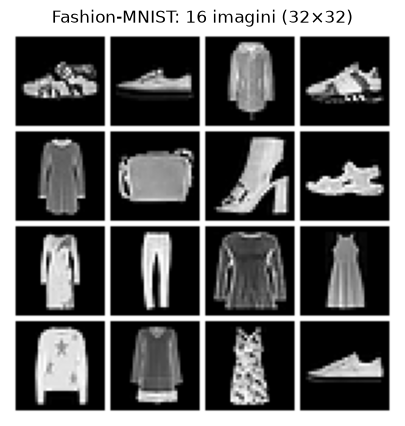

['Sandal', 'Sneaker', 'Coat', 'Sneaker', 'Dress', 'Bag', 'Ankle boot', 'Sandal', 'Dress', 'Trouser', 'Pullover', 'Dress', 'Pullover', 'Dress', 'Dress', 'Sneaker']


In [3]:
def to01(x):
    # din [-1, 1] înapoi în [0, 1], doar pentru afișare
    return ((x.clamp(-1, 1) + 1) / 2).cpu()

def show_grid(x, nrow, title, path=None, size=6):
    grid = make_grid(to01(x), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(size, size))
    plt.imshow(grid.permute(1, 2, 0), cmap="gray")
    plt.title(title); plt.axis("off")
    if path: plt.savefig(path, bbox_inches="tight", dpi=120)
    plt.show()

classes = train_ds.classes
show_grid(x_batch[:16], nrow=4, title="Fashion-MNIST: 16 imagini (32×32)", path="outputs/s1_date.png", size=5)
print([classes[i] for i in y_batch[:16].tolist()])

**Interpretare.** Imaginile sunt 32×32, cu un chenar negru de 2 pixeli adăugat de `Pad`. Valorile sunt exact în [−1, 1], deci sunt pe aceeași scară cu zgomotul gaussian.

## Sarcina 2 — Procesul direct

Programul de zgomot stabilește cât zgomot se adaugă la fiecare pas: $\beta_t$. Din el calculăm:

- $\alpha_t = 1 - \beta_t$;
- $\bar\alpha_t = \alpha_1 \cdot \alpha_2 \cdots \alpha_t$ (`torch.cumprod`), adică cât din imaginea originală „supraviețuiește” până la pasul $t$.

Comparăm două programe, ambele cu $T = 1000$:

- **liniar** (Ho et al., 2020): $\beta_t$ crește uniform de la 0,0001 la 0,02;
- **cosinus** (Nichol & Dhariwal, 2021): definim direct $\bar\alpha_t = f(t)/f(0)$, cu $f(t) = \cos^2\!\left(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\right)$, $s = 0{,}008$. Apoi $\beta_t = 1 - \bar\alpha_t/\bar\alpha_{t-1}$, limitat superior la 0,999.

Proprietatea esențială este că putem obține **direct** imaginea zgomotoasă de la orice pas $t$:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\, \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

În cod pașii sunt indexați 0…999: indexul $i$ corespunde pasului $t = i+1$ din formule.

In [4]:
T = 1000

class Schedule:
    # Toate mărimile derivate dintr-un program de zgomot, păstrate pe dispozitiv
    def __init__(self, betas, name):
        self.name = name
        self.betas = betas.float().to(device)
        self.alphas = 1.0 - self.betas
        self.alpha_bar = torch.cumprod(self.alphas, dim=0)
        self.sqrt_ab = self.alpha_bar.sqrt()
        self.sqrt_1m_ab = (1.0 - self.alpha_bar).sqrt()

def linear_betas(T, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T, dtype=torch.float64)

def cosine_betas(T, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64)          # t = 0, 1, ..., T
    f = torch.cos(((t / T + s) / (1 + s)) * math.pi / 2) ** 2
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(max=0.999)

sched_lin = Schedule(linear_betas(T), "liniar")
sched_cos = Schedule(cosine_betas(T), "cosinus")

def q_sample(x0, t, eps, sched):
    # x_t = sqrt(ᾱ_t)·x0 + sqrt(1-ᾱ_t)·ε ; t este un tensor (B,) cu indecși 0..T-1
    a = sched.sqrt_ab[t][:, None, None, None]
    b = sched.sqrt_1m_ab[t][:, None, None, None]
    return a * x0 + b * eps

for s in (sched_lin, sched_cos):
    print(f"{s.name:8}: beta[0]={s.betas[0].item():.6f}  beta[-1]={s.betas[-1].item():.4f}  "
          f"ᾱ la final={s.alpha_bar[-1].item():.2e}")

liniar  : beta[0]=0.000100  beta[-1]=0.0200  ᾱ la final=4.04e-05
cosinus : beta[0]=0.000041  beta[-1]=0.9990  ᾱ la final=2.43e-09


**Aceeași imagine la t = 0, 50, 100, 250, 500, 750, 999, pentru ambele programe.** Folosim același $\varepsilon$, ca singura diferență între rânduri să fie programul de zgomot.

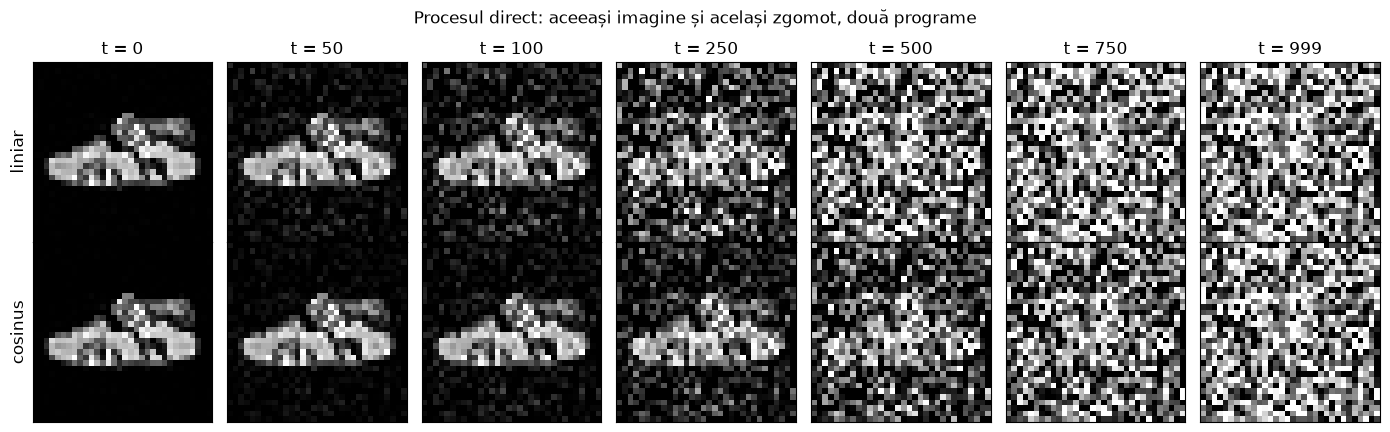

In [5]:
set_seed()
x0 = x_batch[:1].to(device)                      # o singură imagine
eps = torch.randn_like(x0)
t_show = [0, 50, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(2, len(t_show), figsize=(14, 4.4))
for r, s in enumerate((sched_lin, sched_cos)):
    for c, t in enumerate(t_show):
        xt = q_sample(x0, torch.tensor([t], device=device), eps, s)
        axes[r, c].imshow(to01(xt)[0, 0], cmap="gray")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(f"t = {t}")
    axes[r, 0].set_ylabel(s.name, fontsize=12)
fig.suptitle("Procesul direct: aceeași imagine și același zgomot, două programe")
plt.tight_layout(); plt.savefig("outputs/s2_proces_direct.png", dpi=120); plt.show()

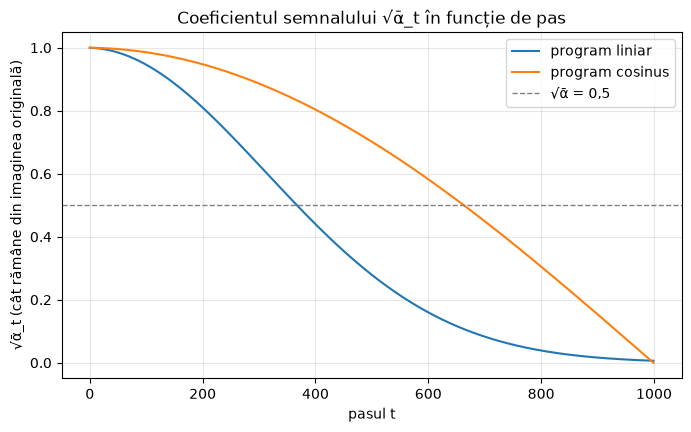

Programul liniar  : √ᾱ_t scade sub 0,5 la pasul t = 368
Programul cosinus : √ᾱ_t scade sub 0,5 la pasul t = 664


In [6]:
steps = np.arange(T)
plt.figure(figsize=(8, 4.5))
for s, col in ((sched_lin, "tab:blue"), (sched_cos, "tab:orange")):
    plt.plot(steps, s.sqrt_ab.cpu().numpy(), label=f"program {s.name}", color=col)
plt.axhline(0.5, color="gray", ls="--", lw=1, label="√ᾱ = 0,5")
plt.xlabel("pasul t"); plt.ylabel("√ᾱ_t (cât rămâne din imaginea originală)")
plt.title("Coeficientul semnalului √ᾱ_t în funcție de pas")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("outputs/s2_sqrt_alpha_bar.png", dpi=120, bbox_inches="tight"); plt.show()

prag = {}
for s in (sched_lin, sched_cos):
    prag[s.name] = int((s.sqrt_ab < 0.5).nonzero()[0].item())
    print(f"Programul {s.name:8}: √ᾱ_t scade sub 0,5 la pasul t = {prag[s.name]}")

**Interpretare.**

- În grilă, la programul **liniar** pantoful abia se mai distinge la t = 250 și dispare complet la t = 500. La programul **cosinus** pantoful e încă clar la t = 250 și se mai ghicește la t = 500.
- Graficul confirmă diferența: √ᾱₜ scade sub 0,5 (adică imaginea originală contribuie cu mai puțin de jumătate) la **t = 368** pentru programul liniar și abia la **t = 664** pentru cosinus.
- Programul liniar distruge informația prea repede: de la t = 673 încolo (ultimii ~330 de pași) √ᾱ e sub 0,1, deci imaginea arată deja aproape ca zgomotul pur. La cosinus, acest prag e atins abia la t = 935. Cosinusul distribuie distrugerea mai uniform, deci rețeaua învață pe mai multe niveluri utile de zgomot.
- La final, ambele programe ajung practic la zgomot pur: ᾱ₉₉₉ = 4·10⁻⁵ (liniar) și 2·10⁻⁹ (cosinus).

## Sarcina 3 — Rețeaua U-Net (cod dat)

Codul este cel din condiție. Am adăugat doar comentarii care marchează trei lucruri:

- **unde intră pasul t**: `time_embedding` transformă numărul pasului într-un vector sinusoidal de 128 de valori, `t_mlp` îl prelucrează, iar în fiecare `ResBlock` stratul `t_proj` îl adună peste hărțile de trăsături;
- **conexiunile skip**: `torch.cat([...], dim=1)` în partea de urcare lipește trăsăturile de la aceeași rezoluție din partea de coborâre;
- **conexiunile reziduale**: `h + self.skip(x)` la ieșirea fiecărui `ResBlock`.

In [7]:
def time_embedding(t, dim=128):
    # t: tensor (B,) cu pașii; întoarce (B, dim)
    # >>> AICI intră PASUL t: numărul pasului devine un vector sinusoidal
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)   # pasul t intră aici
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]   # >>> PASUL t adunat pe fiecare canal
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                  # >>> conexiune REZIDUALĂ

class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128), t_dim=128):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))  # >>> prelucrarea pasului t
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.down1 = ResBlock(ch[0], ch[0])
        self.down2 = ResBlock(ch[0], ch[1])
        self.down3 = ResBlock(ch[1], ch[2])
        self.mid = ResBlock(ch[2], ch[2])
        self.up3 = ResBlock(2 * ch[2], ch[1])
        self.up2 = ResBlock(2 * ch[1], ch[0])
        self.up1 = ResBlock(2 * ch[0], ch[0])
        self.out = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x, t):
        temb = self.t_mlp(time_embedding(t))     # >>> PASUL t intră în rețea
        x = self.inp(x)
        s1 = self.down1(x, temb)                                 # 32×32
        s2 = self.down2(F.avg_pool2d(s1, 2), temb)               # 16×16
        s3 = self.down3(F.avg_pool2d(s2, 2), temb)               # 8×8
        h = self.mid(F.avg_pool2d(s3, 2), temb)                  # 4×4
        up = lambda z: F.interpolate(z, scale_factor=2)
        h = self.up3(torch.cat([up(h), s3], dim=1), temb)        # >>> SKIP: concatenare cu s3
        h = self.up2(torch.cat([up(h), s2], dim=1), temb)        # >>> SKIP: concatenare cu s2
        h = self.up1(torch.cat([up(h), s1], dim=1), temb)        # >>> SKIP: concatenare cu s1
        return self.out(h)                                       # zgomotul prezis

In [8]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

test_out = UNet()(torch.randn(8, 1, 32, 32), torch.randint(0, 1000, (8,)))
print("Forma ieșirii:", tuple(test_out.shape))
assert test_out.shape == (8, 1, 32, 32)
print(f"Număr de parametri: {n_params(UNet()):,}")

Forma ieșirii: (8, 1, 32, 32)
Număr de parametri: 979,585


**Interpretare.** Ieșirea are aceeași formă ca intrarea, pentru că rețeaua prezice câte o valoare de zgomot pentru fiecare pixel. Rețeaua are ~0,98 milioane de parametri, adică „aproximativ 1 milion”, cum se aștepta în condiție.

## Sarcina 4 — Antrenarea cu programul liniar

La fiecare lot:

1. alegem pentru fiecare imagine un pas aleator $t \in \{0, \dots, 999\}$;
2. generăm zgomotul $\varepsilon \sim \mathcal{N}(0, I)$;
3. calculăm $x_t$ cu `q_sample`;
4. rețeaua prezice $\varepsilon_\theta(x_t, t)$;
5. pierderea este eroarea pătratică medie $L = \text{media}\left(\lVert \varepsilon - \varepsilon_\theta(x_t, t)\rVert^2\right)$.

**Hiperparametri** (din condiție): Adam, rata de învățare 0,0002, loturi de 128, 15 epoci, seed 42.

- **Rata 2·10⁻⁴** este valoarea folosită de Ho et al. Una mai mare face antrenarea instabilă, una mai mică o face prea lentă pentru 15 epoci.
- Pasul $t$ ales aleator face ca, într-o singură epocă, rețeaua să vadă toate nivelurile de zgomot.

Funcția `train` este refolosită la Sarcina 7 și la bonus. Salvez modelul și istoricul pierderii în `models/`.

In [9]:
def train(sched, ch=(32, 64, 128), epochs=15, lr=2e-4, tag="model"):
    path_w, path_h = f"models/{tag}.pt", f"models/{tag}_istoric.json"
    model = UNet(ch=ch).to(device)
    if os.path.exists(path_w) and os.path.exists(path_h) and not RETRAIN:
        model.load_state_dict(torch.load(path_w, map_location=device))
        hist = json.load(open(path_h))
        print(f"[{tag}] model încărcat din {path_w} (antrenat anterior în {hist['timp_s']:.0f} s)")
        return model.eval(), hist["losses"], hist["timp_s"]

    set_seed()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    sync(); t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for x0, _ in train_loader:
            x0 = x0.to(device)
            t = torch.randint(0, T, (x0.shape[0],), device=device)
            eps = torch.randn_like(x0)
            loss = F.mse_loss(model(q_sample(x0, t, eps, sched), t), eps)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); n += 1
        losses.append(tot / n)
        sync(); print(f"[{tag}] epoca {ep:2d}/{epochs}  pierdere medie = {losses[-1]:.4f}  "
                      f"({time.perf_counter() - t_start:.0f} s)")
    sync(); dur = time.perf_counter() - t_start
    torch.save(model.state_dict(), path_w)
    json.dump({"losses": losses, "timp_s": dur}, open(path_h, "w"))
    return model.eval(), losses, dur

model_lin, losses_lin, time_lin = train(sched_lin, tag="ddpm_liniar")
print(f"Timp total de antrenare: {time_lin/60:.1f} min ({time_lin/len(losses_lin):.0f} s/epocă)")

[ddpm_liniar] epoca  1/15  pierdere medie = 0.1050  (54 s)


[ddpm_liniar] epoca  2/15  pierdere medie = 0.0479  (104 s)


[ddpm_liniar] epoca  3/15  pierdere medie = 0.0427  (156 s)


[ddpm_liniar] epoca  4/15  pierdere medie = 0.0403  (209 s)


[ddpm_liniar] epoca  5/15  pierdere medie = 0.0385  (263 s)


[ddpm_liniar] epoca  6/15  pierdere medie = 0.0375  (316 s)


... (5 outputs left out)

[ddpm_liniar] epoca 12/15  pierdere medie = 0.0337  (639 s)


[ddpm_liniar] epoca 13/15  pierdere medie = 0.0337  (691 s)


[ddpm_liniar] epoca 14/15  pierdere medie = 0.0334  (743 s)


[ddpm_liniar] epoca 15/15  pierdere medie = 0.0328  (798 s)
Timp total de antrenare: 13.3 min (53 s/epocă)


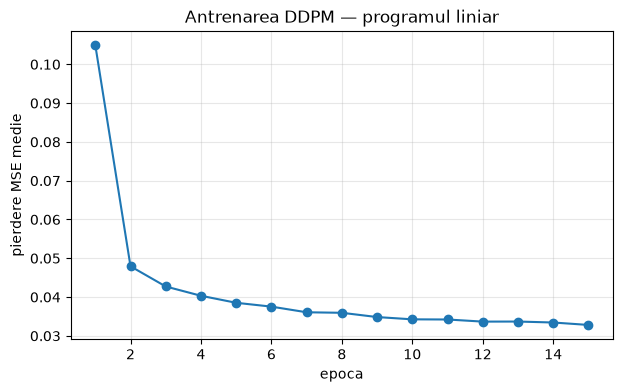

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(losses_lin) + 1), losses_lin, marker="o")
plt.xlabel("epoca"); plt.ylabel("pierdere MSE medie")
plt.title("Antrenarea DDPM — programul liniar")
plt.grid(alpha=0.3); plt.savefig("outputs/s4_pierdere.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretare.**

- Pierderea scade brusc în prima epocă (de la 0,105 la 0,048 în epoca a 2-a), apoi coboară lent până la **0,0328** în epoca 15. După epoca 10 câștigul pe epocă e sub 0,001, deci modelul e aproape de platou pentru această arhitectură.
- Curba e netedă, fără salturi, deci rata de învățare 2·10⁻⁴ e stabilă.
- Timp: **13,3 minute** pe MPS (Apple M3), aproximativ 53 s pe epocă.
- Pierderea **nu** ajunge la 0 și nici nu poate: la pașii mici ($t$ aproape de 0) zgomotul adăugat e foarte slab și aproape imposibil de separat exact de detaliile fine ale imaginii.

## Sarcina 5 — Generarea DDPM (algoritmul 2 din Ho et al., 2020)

Pornim de la zgomot pur $x_T \sim \mathcal{N}(0, I)$ și parcurgem $t = 999, 998, \dots, 0$. La fiecare pas:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t, t)\right) + \sigma_t z, \qquad \sigma_t^2 = \beta_t,\; z \sim \mathcal{N}(0, I)$$

La ultimul pas ($t = 0$) nu mai adăugăm zgomot ($z = 0$). Pentru generare folosim `model.eval()` și `torch.no_grad()`: nu antrenăm, deci nu avem nevoie de gradienți.

DDPM, 1000 de pași, 64 de imagini: 17.1 s


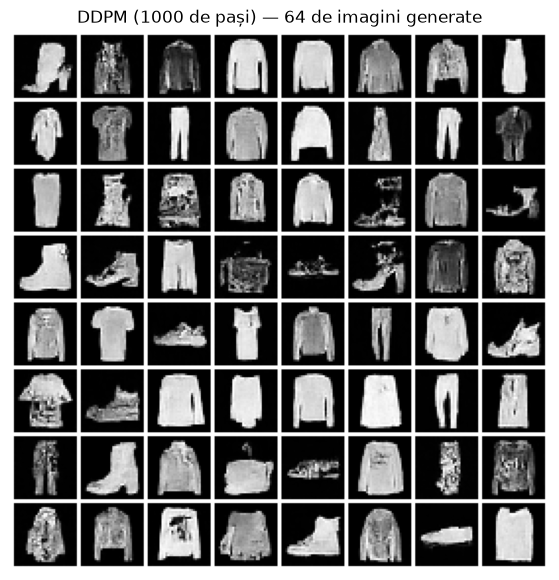

In [11]:
@torch.no_grad()
def ddpm_sample(model, sched, x_T, save_at=()):
    model.eval()
    x = x_T.clone()
    traj = {}
    for t in range(T - 1, -1, -1):
        if t in save_at: traj[t] = x[0].clone()
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        mean = (x - sched.betas[t] / sched.sqrt_1m_ab[t] * eps) / sched.alphas[t].sqrt()
        if t > 0:
            x = mean + sched.betas[t].sqrt() * torch.randn_like(x)
        else:
            x = mean                                  # ultimul pas: fără zgomot
    traj["final"] = x[0].clone()
    return x, traj

# Același zgomot de pornire, refolosit la toate comparațiile de mai jos
g = torch.Generator().manual_seed(SEED)
x_T = torch.randn(64, 1, 32, 32, generator=g).to(device)

set_seed()
save_at = [999, 850, 700, 500, 300, 150, 50]
sync(); t0 = time.perf_counter()
samples_ddpm, traj = ddpm_sample(model_lin, sched_lin, x_T, save_at=save_at)
sync(); time_ddpm = time.perf_counter() - t0
print(f"DDPM, 1000 de pași, 64 de imagini: {time_ddpm:.1f} s")
show_grid(samples_ddpm, nrow=8, title="DDPM (1000 de pași) — 64 de imagini generate", path="outputs/s5_ddpm_64.png", size=7)

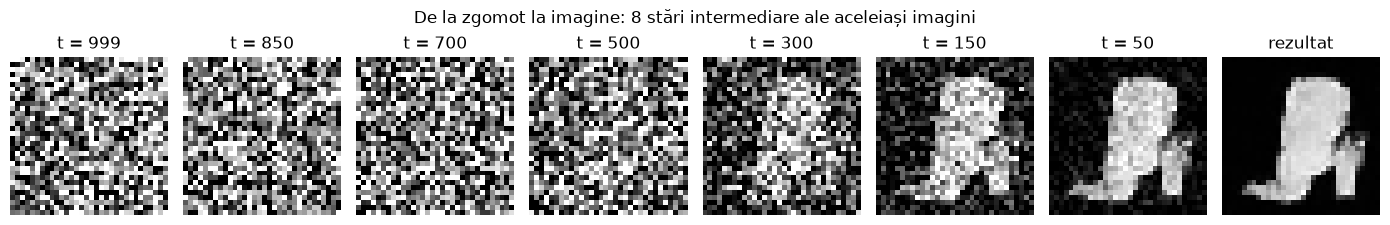

In [12]:
keys = save_at + ["final"]
fig, axes = plt.subplots(1, len(keys), figsize=(14, 2.3))
for ax, k in zip(axes, keys):
    ax.imshow(to01(traj[k])[0], cmap="gray"); ax.axis("off")
    ax.set_title(f"t = {k}" if k != "final" else "rezultat")
fig.suptitle("De la zgomot la imagine: 8 stări intermediare ale aceleiași imagini")
plt.tight_layout(); plt.savefig("outputs/s5_traiectorie.png", dpi=120); plt.show()

**Interpretare.**

- **Grila de 64 de imagini:** se recunosc clar majoritatea claselor Fashion-MNIST: pulovere, tricouri, pantaloni, rochii, adidași, sandale, ghete, genți. Formele sunt corecte, însă texturile sunt uneori pătate sau prea luminoase, iar câteva imagini sunt amestecuri greu de încadrat (de exemplu o haină cu textură „zdrențuită”).
- **Traiectoria:** până la t ≈ 500 nu se vede nimic, doar zgomot. Silueta (o gheată) apare în jurul lui t = 300, este clară la t = 150, iar ultimii ~50 de pași doar curăță zgomotul fin rămas. Forma generală se decide la nivelurile mari de zgomot, iar detaliile la cele mici.
- **Timp:** 17,1 s pentru 64 de imagini (1000 de evaluări ale rețelei).

## Sarcina 6 — Mai puțini pași cu DDIM

DDIM (Song et al., 2021) folosește **aceeași rețea antrenată**, dar o eșantionare deterministă care poate sări peste pași. Alegem un șir rar de pași `torch.linspace(999, 0, n)`. Pentru fiecare pereche de pași consecutivi $t \to t'$:

$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}, \qquad x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'}}\,\varepsilon_\theta(x_t,t)$$

La ultimul pas rezultatul este direct $\hat x_0$.

- Aici implementez formulele exact ca mai sus, fără nicio limitare a lui $\hat x_0$ (`clip=False`).
- Funcția are și opțiunea `clip=True`, folosită la Sarcina 7: limitează $\hat x_0$ la [−1, 1] și **recalculează** zgomotul din valoarea limitată, $\hat\varepsilon = (x_t - \sqrt{\bar\alpha_t}\,\hat x_0)/\sqrt{1-\bar\alpha_t}$, ca cele două mărimi să rămână consistente (așa face și biblioteca `diffusers`). Am încercat la început să limitez $\hat x_0$ fără să recalculez $\varepsilon$. Rezultatul: la 1000 și 200 de pași eroarea se acumula și imaginile ieșeau stricate.
- Toate rulările pornesc de la **același zgomot** `x_T`, ca diferențele să vină doar din numărul de pași.

In [13]:
@torch.no_grad()
def ddim_sample(model, sched, x_T, n_steps, clip=False):
    model.eval()
    ts = torch.linspace(T - 1, 0, n_steps).long().tolist()
    x = x_T.clone()
    for i, t in enumerate(ts):
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        x0_hat = (x - sched.sqrt_1m_ab[t] * eps) / sched.sqrt_ab[t]
        if clip:
            x0_hat = x0_hat.clamp(-1, 1)
            eps = (x - sched.sqrt_ab[t] * x0_hat) / sched.sqrt_1m_ab[t]   # zgomotul consistent cu x̂0 limitat
        if i == len(ts) - 1:
            x = x0_hat
        else:
            t2 = ts[i + 1]
            x = sched.sqrt_ab[t2] * x0_hat + sched.sqrt_1m_ab[t2] * eps
    return x

def timed(fn, *args, **kw):
    sync(); t0 = time.perf_counter()
    out = fn(*args, **kw)
    sync(); return out, time.perf_counter() - t0

ddim_res = {}
for n in [1000, 200, 50, 20, 10]:
    ddim_res[n], dt = timed(ddim_sample, model_lin, sched_lin, x_T, n)
    ddim_res[n] = (ddim_res[n], dt)
    print(f"DDIM {n:4d} pași: {dt:6.2f} s")

tab6 = pd.DataFrame(
    [{"Metodă": "DDPM", "Pași": 1000, "Timp pentru 64 de imagini (s)": round(time_ddpm, 2)}] +
    [{"Metodă": "DDIM", "Pași": n, "Timp pentru 64 de imagini (s)": round(ddim_res[n][1], 2)} for n in [1000, 200, 50, 20, 10]])
tab6

DDIM 1000 pași:  16.63 s


DDIM  200 pași:   3.35 s


DDIM   50 pași:   0.84 s


DDIM   20 pași:   0.33 s
DDIM   10 pași:   0.17 s


,Metodă,Pași,Timp pentru 64 de imagini (s)
0,DDPM,1000,17.07
1,DDIM,1000,16.63
2,DDIM,200,3.35
3,DDIM,50,0.84
4,DDIM,20,0.33
5,DDIM,10,0.17


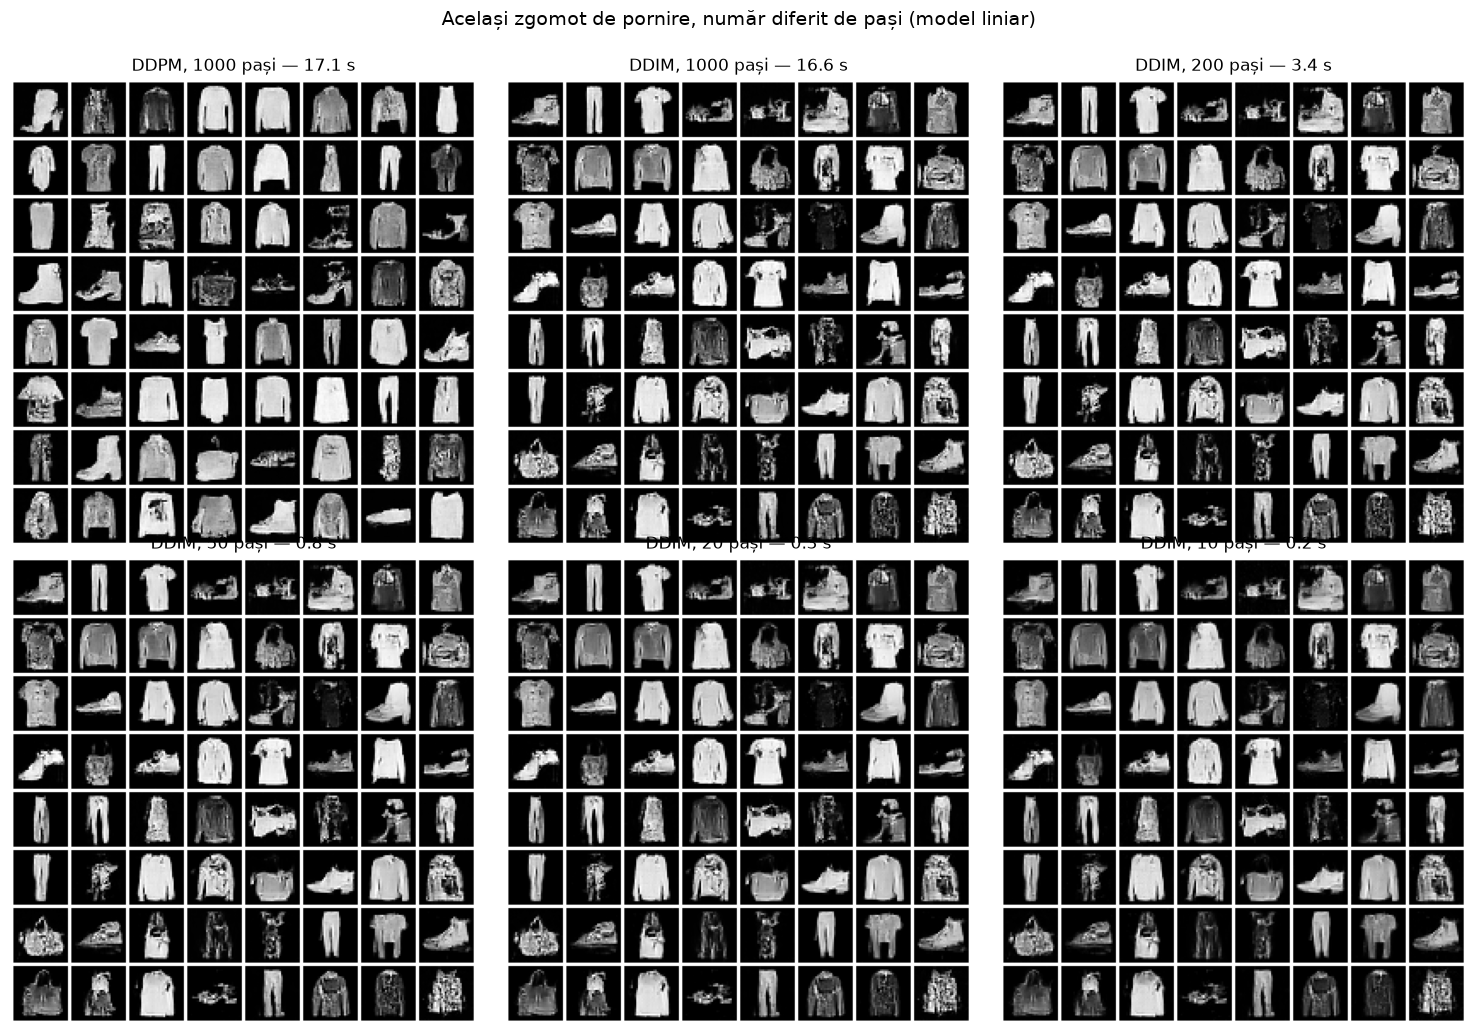

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10.5))
panels = [("DDPM, 1000 pași", samples_ddpm, time_ddpm)] + [(f"DDIM, {n} pași", *ddim_res[n]) for n in [1000, 200, 50, 20, 10]]
for ax, (title, imgs, dt) in zip(axes.flat, panels):
    grid = make_grid(to01(imgs), nrow=8, padding=2, pad_value=1.0)
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off"); ax.set_title(f"{title} — {dt:.1f} s")
fig.suptitle("Același zgomot de pornire, număr diferit de pași (model liniar)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.savefig("outputs/s6_ddpm_vs_ddim.png", dpi=110); plt.show()

# Salvez și fiecare grilă separat, pentru examinarea calității
for n in [1000, 200, 50, 20, 10]:
    grid = make_grid(to01(ddim_res[n][0]), nrow=8, padding=2, pad_value=1.0)
    plt.imsave(f"outputs/s6_ddim_{n}.png", grid.permute(1, 2, 0).numpy())

**Tabelul DDPM / DDIM** (timpii sunt cei măsurați mai sus; calitatea vizuală 1–5 am notat-o după examinarea grilelor):

| Metodă | Pași | Timp pentru 64 de imagini (s) | Calitate vizuală (1–5) | Observații |
|---|---|---|---|---|
| DDPM | 1000 | 17,07 | 4 | Forme clare și variate; unele texturi pătate. Fiind stocastic, produce alte haine decât DDIM din același zgomot de pornire. |
| DDIM | 1000 | 16,63 | 4 | Calitate similară cu DDPM, aceleași obiecte ca la DDIM cu mai puțini pași |
| DDIM | 200 | 3,35 | 4 | Practic identic cu DDIM 1000, de 5 ori mai rapid |
| DDIM | 50 | 0,84 | 4 | Încă foarte apropiat de DDIM 1000; diferențe doar în detalii fine |
| DDIM | 20 | 0,33 | 4 | Aceleași obiecte; texturi ceva mai netede |
| DDIM | 10 | 0,17 | 3 | Aceleași siluete, dar mai puține detalii, margini mai moi, câteva obiecte mai „spălăcite” |

**Interpretare.**

- **Timpul este proporțional cu numărul de pași** (~0,017 s pe pas, pentru 64 de imagini), pentru că fiecare pas înseamnă o evaluare completă a rețelei. De la 1000 la 10 pași generarea devine de **100 de ori mai rapidă**.
- **DDIM este determinist:** pornind din același `x_T`, toate variantele DDIM produc *aceleași* haine (aceeași poziție în grilă), doar cu mai mult sau mai puțin detaliu. DDPM adaugă zgomot nou la fiecare pas, deci ajunge la alte imagini.
- **Calitatea scade mult mai încet decât timpul:** între 1000 și 50 de pași diferența abia se vede, iar o degradare clară apare abia la 10 pași. Pentru acest model, **20–50 de pași DDIM** sunt compromisul optim.

## Sarcina 7 — Liniar vs. cosinus

Antrenez un al doilea model **identic**: aceeași rețea, 15 epoci, Adam 2·10⁻⁴, seed 42. Se schimbă un singur lucru, programul de zgomot (cosinus). Apoi generez cu DDIM la 50 și la 20 de pași, din același zgomot de pornire, cu ambele modele.

In [15]:
model_cos, losses_cos, time_cos = train(sched_cos, tag="ddpm_cosinus")
print(f"Timp total de antrenare: {time_cos/60:.1f} min")

[ddpm_cosinus] epoca  1/15  pierdere medie = 0.1400  (55 s)


[ddpm_cosinus] epoca  2/15  pierdere medie = 0.0815  (112 s)


[ddpm_cosinus] epoca  3/15  pierdere medie = 0.0736  (168 s)


[ddpm_cosinus] epoca  4/15  pierdere medie = 0.0699  (225 s)


[ddpm_cosinus] epoca  5/15  pierdere medie = 0.0673  (282 s)


[ddpm_cosinus] epoca  6/15  pierdere medie = 0.0656  (339 s)


... (5 outputs left out)

[ddpm_cosinus] epoca 12/15  pierdere medie = 0.0599  (689 s)


[ddpm_cosinus] epoca 13/15  pierdere medie = 0.0600  (747 s)


[ddpm_cosinus] epoca 14/15  pierdere medie = 0.0596  (805 s)


[ddpm_cosinus] epoca 15/15  pierdere medie = 0.0588  (863 s)
Timp total de antrenare: 14.4 min


**Mai întâi, DDIM exact ca la Sarcina 6 (fără limitare).** Primul pas DDIM pornește de la $t = 999$ și calculează $\hat x_0$ împărțind la $\sqrt{\bar\alpha_{999}}$. Cele două programe dau valori foarte diferite aici.

liniar  : √ᾱ_999 = 6.35e-03  →  max |x̂0| la primul pas DDIM =     22.0
cosinus : √ᾱ_999 = 4.93e-05  →  max |x̂0| la primul pas DDIM =   2938.6


Cosinus, DDIM 50 fără limitare: valori în [-445.5, 438.1] (ar trebui [−1, 1])


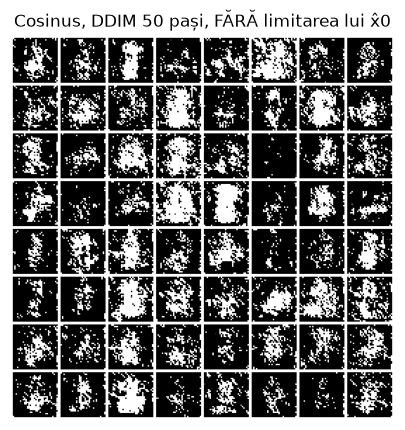

In [16]:
for s, m in ((sched_lin, model_lin), (sched_cos, model_cos)):
    with torch.no_grad():
        eps = m(x_T, torch.full((64,), T - 1, device=device, dtype=torch.long))
        x0_hat = (x_T - s.sqrt_1m_ab[T - 1] * eps) / s.sqrt_ab[T - 1]
    print(f"{s.name:8}: √ᾱ_999 = {s.sqrt_ab[T-1].item():.2e}  →  max |x̂0| la primul pas DDIM = {x0_hat.abs().max().item():8.1f}")

cos_noclip = ddim_sample(model_cos, sched_cos, x_T, 50, clip=False)
print(f"Cosinus, DDIM 50 fără limitare: valori în [{cos_noclip.min().item():.1f}, {cos_noclip.max().item():.1f}] (ar trebui [−1, 1])")
show_grid(cos_noclip, nrow=8, title="Cosinus, DDIM 50 pași, FĂRĂ limitarea lui x̂0", path="outputs/s7_cosinus_50_fara_limitare.png", size=5)

Programul cosinus duce $\bar\alpha_t$ practic la zero la final ($\sqrt{\bar\alpha_{999}} \approx 5\cdot10^{-5}$, față de $6\cdot10^{-3}$ la liniar). Împărțirea la un număr atât de mic amplifică orice mică eroare a rețelei de zeci de mii de ori, așa că $\hat x_0$ „explodează”, iar imaginile ies saturate (doar pixeli albi și negri).

Modelul cosinus nu este însă stricat. Cu DDPM, care nu împarte la $\sqrt{\bar\alpha_t}$, generează imagini corecte (verificăm mai jos). Pentru o comparație corectă între programe, folosesc la ambele modele **același** eșantionator DDIM, cu limitarea consistentă a lui $\hat x_0$ (`clip=True`). La modelul liniar această limitare aproape nu schimbă nimic.

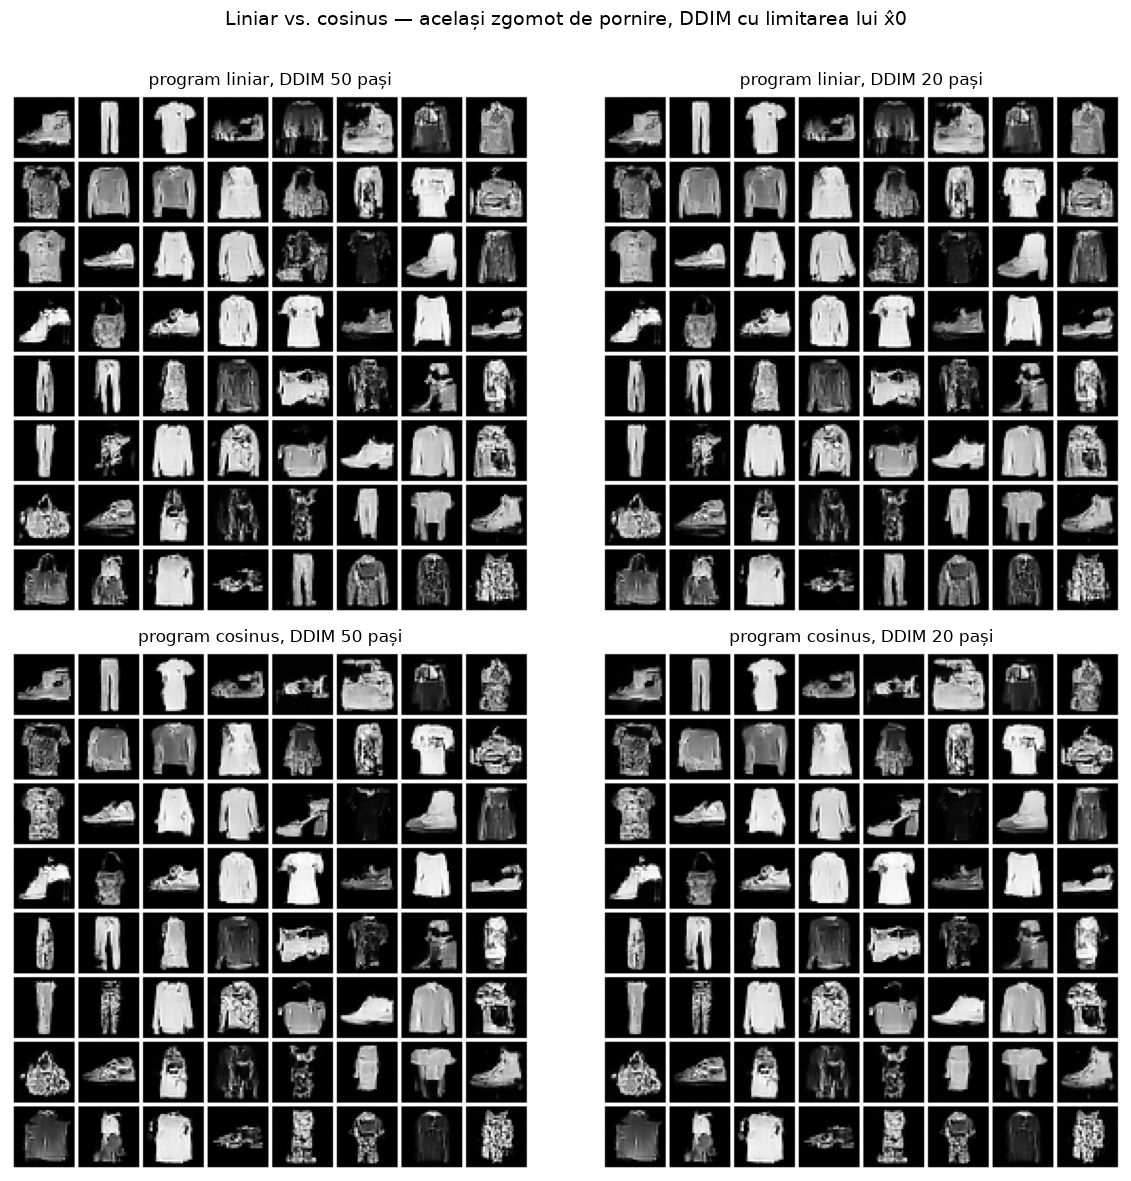

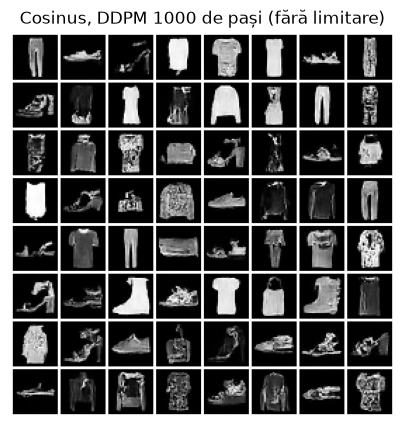

In [17]:
cmp = {}
for name, m, s in (("liniar", model_lin, sched_lin), ("cosinus", model_cos, sched_cos)):
    for n in (50, 20):
        cmp[(name, n)] = ddim_sample(m, s, x_T, n, clip=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for r, name in enumerate(("liniar", "cosinus")):
    for c, n in enumerate((50, 20)):
        grid = make_grid(to01(cmp[(name, n)]), nrow=8, padding=2, pad_value=1.0)
        axes[r, c].imshow(grid.permute(1, 2, 0)); axes[r, c].axis("off")
        axes[r, c].set_title(f"program {name}, DDIM {n} pași")
        plt.imsave(f"outputs/s7_{name}_{n}.png", grid.permute(1, 2, 0).numpy())
fig.suptitle("Liniar vs. cosinus — același zgomot de pornire, DDIM cu limitarea lui x̂0", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.savefig("outputs/s7_comparatie.png", dpi=110); plt.show()

# Verificare: modelul cosinus generează corect și cu DDPM (1000 de pași, fără nicio limitare)
set_seed()
cos_ddpm, _ = ddpm_sample(model_cos, sched_cos, x_T)
show_grid(cos_ddpm, nrow=8, title="Cosinus, DDPM 1000 de pași (fără limitare)", path="outputs/s7_cosinus_ddpm.png", size=5)

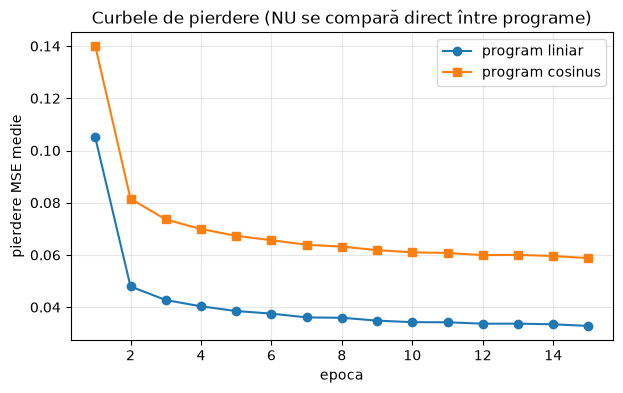

Pierderea finală: liniar = 0.0328 | cosinus = 0.0588


In [18]:
ep = range(1, len(losses_lin) + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, losses_lin, marker="o", label="program liniar")
plt.plot(ep, losses_cos, marker="s", label="program cosinus")
plt.xlabel("epoca"); plt.ylabel("pierdere MSE medie")
plt.title("Curbele de pierdere (NU se compară direct între programe)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("outputs/s7_pierderi.png", dpi=120, bbox_inches="tight"); plt.show()
print(f"Pierderea finală: liniar = {losses_lin[-1]:.4f} | cosinus = {losses_cos[-1]:.4f}")

**Atenție:** valorile pierderii nu sunt direct comparabile între cele două programe. Media se face peste niveluri de zgomot diferite: pentru același $t$, cele două programe produc $x_t$ cu proporții diferite de semnal și zgomot, deci sarcina rețelei are altă dificultate. Modelele se compară după imaginile generate.

**Note vizuale** (după examinarea grilelor; ambele modele cu DDIM cu limitarea consistentă a lui x̂₀):

| Model | DDIM 50 pași | DDIM 20 pași | Observații |
|---|---|---|---|
| liniar | 4 | 4 | Forme curate; unele texturi pătate |
| cosinus | 4 | 4 | Aceleași categorii de obiecte; texturi și modele (dungi, imprimeuri) puțin mai bogate, dar și câteva obiecte mai „zgomotoase” |

**Interpretare.**

- **Calitatea finală:** după 15 epoci, cu limitarea consistentă, cele două modele dau imagini de calitate comparabilă. Nu văd un câștigător clar la această rezoluție mică (32×32) și cu un antrenament scurt. Programul cosinus pare să păstreze ceva mai mult detaliu de textură.
- **Diferența mare e la stabilitatea eșantionării.** Programul cosinus duce √ᾱ₉₉₉ la 4,9·10⁻⁵, față de 6,4·10⁻³ la liniar, deci de 130 de ori mai mic. Primul pas DDIM împarte la această valoare, așa că x̂₀ ajunge la ~2900 (față de ~22 la liniar). Fără limitarea lui x̂₀, DDIM cu modelul cosinus produce doar pixeli saturați.
- **Verificarea:** DDPM, care nu împarte la √ᾱ, generează imagini corecte cu același model cosinus. Deci problema ține de eșantionator, nu de model.
- **Pierderile:** pierderea finală e 0,0328 la liniar și 0,0588 la cosinus. Asta **nu** înseamnă că modelul liniar e mai bun. Programul liniar petrece mulți pași aproape de zgomotul pur, unde prezicerea zgomotului e trivială ($x_t \approx \varepsilon$), iar acești pași trag media pierderii în jos.

## Bonus — o rețea mai mică: `UNet(ch=(16, 32, 64))`

Același program liniar și aceleași setări; se schimbă doar lățimea rețelei (numărul de canale pe fiecare nivel).

[ddpm_liniar_mic] epoca  1/15  pierdere medie = 0.1485  (27 s)


[ddpm_liniar_mic] epoca  2/15  pierdere medie = 0.0576  (63 s)


[ddpm_liniar_mic] epoca  3/15  pierdere medie = 0.0496  (105 s)


[ddpm_liniar_mic] epoca  4/15  pierdere medie = 0.0464  (146 s)


[ddpm_liniar_mic] epoca  5/15  pierdere medie = 0.0441  (189 s)


[ddpm_liniar_mic] epoca  6/15  pierdere medie = 0.0427  (231 s)


... (6 outputs left out)

[ddpm_liniar_mic] epoca 13/15  pierdere medie = 0.0377  (487 s)


[ddpm_liniar_mic] epoca 14/15  pierdere medie = 0.0375  (529 s)


[ddpm_liniar_mic] epoca 15/15  pierdere medie = 0.0369  (569 s)


,Rețea,Parametri,Timp antrenare (min),Pierdere finală
0,"UNet(32, 64, 128)",979585,13.3,0.0328
1,"UNet(16, 32, 64)",286145,9.5,0.0369


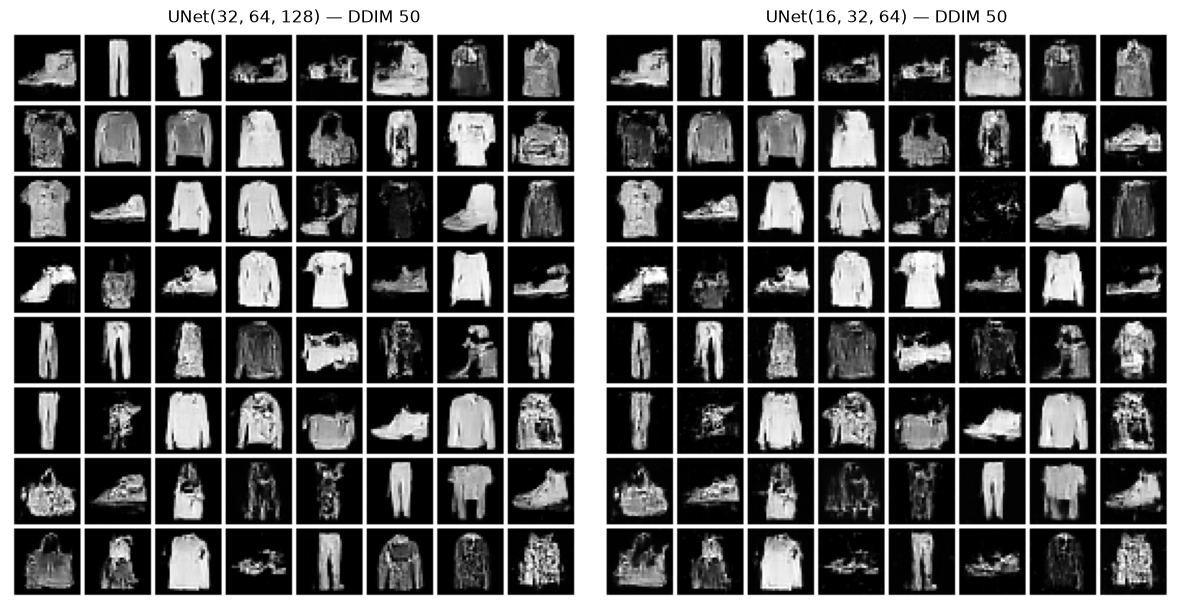

In [18]:
model_small, losses_small, time_small = train(sched_lin, ch=(16, 32, 64), tag="ddpm_liniar_mic")
small_50 = ddim_sample(model_small, sched_lin, x_T, 50)

tab_b = pd.DataFrame([
    {"Rețea": "UNet(32, 64, 128)", "Parametri": n_params(model_lin), "Timp antrenare (min)": round(time_lin / 60, 1),
     "Pierdere finală": round(losses_lin[-1], 4)},
    {"Rețea": "UNet(16, 32, 64)", "Parametri": n_params(model_small), "Timp antrenare (min)": round(time_small / 60, 1),
     "Pierdere finală": round(losses_small[-1], 4)},
])
display(tab_b)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (title, imgs) in zip(axes, (("UNet(32, 64, 128) — DDIM 50", ddim_res[50][0]), ("UNet(16, 32, 64) — DDIM 50", small_50))):
    grid = make_grid(to01(imgs), nrow=8, padding=2, pad_value=1.0)
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.savefig("outputs/bonus_mic_vs_mare.png", dpi=110); plt.show()
plt.imsave("outputs/bonus_mic_50.png", make_grid(to01(small_50), nrow=8, padding=2, pad_value=1.0).permute(1, 2, 0).numpy())

**Interpretare.**

| | UNet(32, 64, 128) | UNet(16, 32, 64) |
|---|---|---|
| Parametri | 979.585 | 286.145 (de 3,4 ori mai puțini) |
| Timp antrenare (15 epoci) | 13,3 min | 9,5 min |
| Pierdere finală | 0,0328 | 0,0369 |
| Calitate vizuală (DDIM 50) | 4 | 3 |

- Rețeaua mică generează aceleași tipuri de obiecte, dar mai neclare și mai întunecate. Mai multe imagini sunt eșuate sau doar parțial formate (de exemplu o haină aproape invizibilă în rândul 3).
- Câștigul de timp e mai mic decât raportul numărului de parametri (9,5 față de 13,3 min, nu de 3,4 ori mai puțin). La rețele atât de mici, pe GPU contează mult costurile fixe: încărcarea datelor, lansarea operațiilor și normalizarea.
- Concluzie: pentru Fashion-MNIST, rețeaua de ~1 milion de parametri merită timpul suplimentar.

## Întrebări de control

**1. De ce procesul direct nu are parametri învățați? Ce rol are în antrenare?**

Procesul direct e definit complet de programul de zgomot βₜ, ales de noi dinainte: el doar amestecă imaginea cu zgomot gaussian după o formulă fixă. Nu trebuie învățat, pentru că știm exact ce zgomot am adăugat. Tocmai asta îl face util: generează automat perechile de antrenare $(x_t, \varepsilon)$. Rețeaua primește $x_t$ și trebuie să ghicească $\varepsilon$, iar răspunsul corect îl avem gratuit, fără nicio etichetă.

**2. De ce putem sări direct la pasul t, fără să parcurgem pașii anteriori?**

Pentru că suma mai multor zgomote gaussiene independente este tot un zgomot gaussian. Aplicând de $t$ ori formula $x_t = \sqrt{\alpha_t}x_{t-1} + \sqrt{\beta_t}\varepsilon$, toți factorii se înmulțesc și obținem direct $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon$, cu $\bar\alpha_t$ produsul tuturor $\alpha$. Așa am construit la Sarcina 2 grila pentru t = 999 dintr-o singură operație. Fără această proprietate, fiecare exemplu de antrenare ar costa până la 1000 de pași.

**3. De ce rețeaua primește și numărul pasului t? Ce s-ar întâmpla fără el?**

Aceeași imagine zgomotoasă se tratează diferit în funcție de cât zgomot conține. La t = 999 aproape toată imaginea e zgomot, deci rețeaua trebuie să „șteargă” mult; la t = 10 trebuie să atingă doar detaliile fine. Rețeaua poate estima singură nivelul de zgomot doar aproximativ, iar formulele de generare presupun că zgomotul prezis are exact scara pasului t. Fără t, rețeaua ar învăța o medie a tuturor nivelurilor și ar curăța prea mult la pașii mici și prea puțin la cei mari, deci imaginile ar ieși neclare sau zgomotoase. În U-Net, t intră prin `time_embedding` → `t_mlp` → `t_proj`, în fiecare bloc rezidual.

**4. De ce generarea e mult mai lentă decât un pas de antrenare?**

Un pas de antrenare înseamnă o singură trecere prin rețea (plus propagarea înapoi) pentru un nivel de zgomot ales aleator. Generarea DDPM trebuie să parcurgă **secvențial toți cei 1000 de pași**: fiecare pas are nevoie de rezultatul celui anterior, deci nu se pot paraleliza. În măsurătorile mele, 64 de imagini au durat 17,1 s cu DDPM (1000 de evaluări ale rețelei), adică ~0,017 s pe evaluare. O epocă întreagă de antrenare (468 de loturi a câte 128 de imagini) a durat ~53 s.

**5. Ce diferență vedeți între programul liniar și cel cosinus la Sarcinile 2 și 7? Cum o explicați?**

- *Sarcina 2:* cosinusul distruge imaginea mai lent la început. √ᾱ scade sub 0,5 la t = 664, față de t = 368 la liniar, iar în grilă pantoful se vede încă la t = 250–500. Programul liniar petrece ultimii ~330 de pași (de la t = 673) cu √ᾱ < 0,1, aproape de zgomotul pur, deci îi „irosește”; cosinusul ajunge acolo abia la t = 935.
- *Sarcina 7:* calitatea finală e comparabilă (nota 4 pentru ambele). Diferența apare la DDIM: cosinusul ajunge la √ᾱ₉₉₉ = 4,9·10⁻⁵, iar împărțirea la această valoare la primul pas a făcut ca x̂₀ să ajungă la ~2900. Fără limitarea lui x̂₀, imaginile au ieșit saturate.
- *Explicație:* cosinusul are β foarte mic la început (0,00004) și foarte mare la final (până la 0,999). Asta păstrează semnalul mai mult timp, dar face ultimii pași foarte „bruști”.

**6. Ce câștigați și ce pierdeți când reduceți pașii DDIM de la 1000 la 10?**

Câștig: viteza, de la 16,6 s la 0,17 s pentru 64 de imagini, adică de ~100 de ori mai rapid. Pierd: detaliile fine. La 10 pași texturile sunt mai netede, iar marginile mai moi (nota 3, față de 4). Forma generală a obiectelor rămâne aceeași, pentru că DDIM e determinist: același `x_T` dă același obiect. Fiecare pas mare face o aproximare liniară mai grosieră a drumului de la zgomot la imagine. Între 1000 și 50 de pași diferența abia se vede, deci majoritatea pașilor sunt redundanți.

**7. De ce pierderile celor două modele de la Sarcina 7 nu se pot compara direct?**

Pierderea este media erorii pe pași $t$ aleși uniform, dar „dificultatea” unui pas depinde de program. Pentru același $t$, programul liniar produce un $x_t$ mult mai zgomotos decât cosinusul. Când $x_t$ e aproape zgomot pur, prezicerea lui $\varepsilon$ e ușoară ($x_t \approx \varepsilon$). Programul liniar are mulți astfel de pași „ușori”, care scad media. Pierderea lui mai mică (0,0328 față de 0,0588) reflectă deci altă distribuție a sarcinilor, nu un model mai bun. De aceea comparăm modelele după imaginile generate.

## Raport

**Lucrare de laborator nr. 4 — DDPM de la zero** · Daniel Pănuța, IASD 2501 · rulat pe MacBook M3 (PyTorch, MPS)

### Ce s-a predat (conform condiției)

| Cerință | Unde în notebook | Stare |
|---|---|---|
| Grila procesului direct (2 programe), graficul √ᾱ și pașii la care scade sub 0,5 | Sarcina 2 | ✅ t = 368 (liniar), t = 664 (cosinus) |
| Numărul de parametri ai rețelei și codul comentat | Sarcina 3 | ✅ 979.585 parametri; comentarii `>>>` la pasul t, skip și reziduale |
| Graficul pierderii pe epoci | Sarcina 4 | ✅ 0,105 → 0,0328 în 15 epoci, 13,3 min |
| Grila de 64 de imagini DDPM și șirul de stări intermediare | Sarcina 5 | ✅ |
| Tabelul DDPM / DDIM completat | Sarcina 6 | ✅ |
| Comparația liniar vs. cosinus: grile și curbele de pierdere | Sarcina 7 | ✅ |
| Răspunsurile la cele 7 întrebări | Întrebări de control | ✅ |
| Bonus: rețea mai mică | Bonus | ✅ 286.145 parametri |

### Rezultate principale

1. Un U-Net de ~1 milion de parametri, antrenat 15 epoci, generează haine Fashion-MNIST recognoscibile și variate (notă vizuală 4/5).
2. DDIM folosește aceeași rețea și reduce generarea de la 1000 la 20–50 de pași fără pierdere vizibilă de calitate, adică de 20–50 de ori mai rapid. La 10 pași detaliile încep să se piardă.
3. Programul cosinus păstrează informația din imagine mai mult timp (√ᾱ < 0,5 abia la t = 664). După 15 epoci, calitatea imaginilor e comparabilă cu cea a programului liniar.
4. Cu programul cosinus, DDIM e instabil fără limitarea lui x̂₀, pentru că √ᾱ₉₉₉ ≈ 5·10⁻⁵. Problema se rezolvă dacă limităm x̂₀ și recalculăm zgomotul consistent cu el.
5. Rețeaua de 3,4 ori mai mică se antrenează în 9,5 min în loc de 13,3 min, dar generează imagini vizibil mai slabe.

### Observații despre implementare

- Toate experimentele folosesc seed 42 și același zgomot de pornire `x_T`. Un singur parametru e schimbat o dată: numărul de pași, programul de zgomot sau lățimea rețelei.
- Modelele antrenate sunt salvate în `models/` (`ddpm_liniar.pt`, `ddpm_cosinus.pt`, `ddpm_liniar_mic.pt`), iar figurile în `outputs/`.
- Diferență față de condiție: lucrul s-a făcut local pe Apple M3 (MPS), nu pe Colab T4. Timpii sunt măsurați pe acest hardware.

### Concluzie

Modelul de difuzie învață o sarcină simplă și bine definită, prezicerea zgomotului. Din ea apare însă capacitatea de a genera imagini noi pornind de la zgomot pur. Prețul este viteza: generarea are nevoie de multe evaluări secvențiale ale rețelei. DDIM reduce mult acest cost, iar alegerea programului de zgomot influențează atât ce învață modelul, cât și stabilitatea eșantionării.